# Détecteur et Classifieur d'Objets Spatiaux & Débris
Detecteur de Déchets 

Ce notebook prépare le pipeline complet de données avec **Pandas** et **TensorFlow**.
Chaque image contient un **unique objet** (satellite ou débris). Le pipeline génère ainsi deux cibles pour chaque image :
- `class_output` : l'identifiant de la classe (parmi 11 classes)
- `bbox_output` : les 4 coordonnées normalisées `[ymin, xmin, ymax, xmax]`

In [28]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
import yaml

# Configuration globale
IMG_SIZE = 224
BATCH_SIZE = 16

DATA_YAML_PATH = 'data/data.yaml'
with open(DATA_YAML_PATH, 'r', encoding='utf-8') as yaml_file:
    dataset_config = yaml.safe_load(yaml_file)

ORIGINAL_CLASS_NAMES = dataset_config['names']
CLASS_NAMES = ['satellite', 'debris']
NUM_CLASSES = len(CLASS_NAMES)

print(f"TensorFlow version: {tf.__version__}")
print(f"Classes originales : {ORIGINAL_CLASS_NAMES}")
print(f"Classes du modèle : {CLASS_NAMES}")

TensorFlow version: 2.21.0
Classes originales : ['cheops', 'debris', 'double_start', 'earth_observation_sat_1', 'lisa_pathfinder', 'proba_2', 'proba_3_csc', 'proba_3_ocs', 'smart_1', 'soho', 'xmm_newton']
Classes du modèle : ['satellite', 'debris']


## 1. Préparation des DataFrames Pandas

Nous lisons les annotations YOLO (`[class_id, x_center, y_center, width, height]`) et les convertissons directement en `[ymin, xmin, ymax, xmax]`.
Chaque image contenant un unique objet, nous n'avons plus besoin de padding `MAX_BOXES`.


In [29]:
def create_dataset_dataframe(image_dir):
    """
    Lit les annotations YOLO et crée un DataFrame avec une cible binaire.
    Tous les objets sauf debris sont regroupés dans la classe satellite.
    """
    image_paths = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
    records = []

    for img_path in image_paths:
        label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        if os.path.exists(label_path):
            with open(label_path, 'r') as label_file:
                line = label_file.readline().strip()
                if line:
                    parts = line.split()
                    cls_id = int(parts[0])
                    x_c, y_c, box_width, box_height = map(float, parts[1:5])
                    original_class_name = (
                        ORIGINAL_CLASS_NAMES[cls_id]
                        if 0 <= cls_id < len(ORIGINAL_CLASS_NAMES)
                        else 'unknown'
                    )

                    ymin = max(0.0, y_c - (box_height / 2.0))
                    xmin = max(0.0, x_c - (box_width / 2.0))
                    ymax = min(1.0, y_c + (box_height / 2.0))
                    xmax = min(1.0, x_c + (box_width / 2.0))

                    binary_class_id = int(original_class_name == 'debris')
                    records.append({
                        'image_path': img_path,
                        'class_id': cls_id,
                        'class_name': original_class_name,
                        'binary_class_id': binary_class_id,
                        'binary_class_name': CLASS_NAMES[binary_class_id],
                        'ymin': ymin,
                        'xmin': xmin,
                        'ymax': ymax,
                        'xmax': xmax,
                    })

    return pd.DataFrame(records)

# Création des DataFrames
df_train = create_dataset_dataframe('data/train/images')
df_val = create_dataset_dataframe('data/valid/images')
df_test = create_dataset_dataframe('data/test/images')

print(f"Train : {len(df_train)} images")
print(f"Val   : {len(df_val)} images")
print(f"Test  : {len(df_test)} images")
print("Distribution binaire (Train) :")
print(df_train['binary_class_name'].value_counts())
df_train.head()

Train : 2105 images
Val   : 239 images
Test  : 123 images
Distribution binaire (Train) :
binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


,image_path,class_id,class_name,binary_class_id,binary_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0,satellite,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0,satellite,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0,satellite,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0,satellite,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0,satellite,0.030078,0.192578,0.658984,0.585547


In [17]:
df_train

,image_path,class_id,class_name,binary_class_id,binary_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0,satellite,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0,satellite,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0,satellite,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0,satellite,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0,satellite,0.030078,0.192578,0.658984,0.585547
...,...,...,...,...,...,...,...,...,...
2100,data/train/images/img101601_jpg.rf.685459b9385...,10,xmm_newton,0,satellite,0.001172,0.533203,0.492578,0.999609
2101,data/train/images/img101601_jpg.rf.e0f21b69e7c...,10,xmm_newton,0,satellite,0.001172,0.000391,0.492578,0.466797
2102,data/train/images/img101603_jpg.rf.58ceeb658d1...,10,xmm_newton,0,satellite,0.000000,0.473828,0.281250,0.965234
2103,data/train/images/img101603_jpg.rf.ac0a7663547...,10,xmm_newton,0,satellite,0.718750,0.034766,1.000000,0.526172


## 2. Exploration des données (EDA)
Vérifions la distribution des classes dans l'ensemble d'entraînement.


In [30]:
print("Distribution des classes binaires (Train) :")
print(df_train['binary_class_name'].value_counts())

Distribution des classes binaires (Train) :
binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


Lors de l'analyse des données, nous voyons qu'il est nécessaire de faire de l'équilNous voyons que nous avons beaucoup plus de sattelites que de débris, donc nous allons augmenter le nombre de débrs et faire un dossier avec 50% de satellites et 50% de débris. 

Pour cela, nous allons faire une rotation avec les images de débris, on en ajoute donc en faisant des rotations à 45, 60, 90, 180 et 270°. Ainsi, on multiplie la quantité de données que nous  les multiplie par 4 en les faisant tourner 

## 3. Pipeline TensorFlow (`tf.data`)

Nous transformons directement les DataFrames Pandas en `tf.data.Dataset` optimisés via `tf.data.Dataset.from_tensor_slices` :
- Chargement et décodage multithreadés (`AUTOTUNE`)
- Redimensionnement à `IMG_SIZE` et normalisation dans `[0, 1]`
- Sortie au format dictionnaire `{'class_output': ..., 'bbox_output': ...}` prêt pour un modèle multi-tâches (classification + localisation)


In [19]:
def df_to_tf_dataset(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE, is_training=True):
    image_paths = df['image_path'].values
    bboxes = df[['ymin', 'xmin', 'ymax', 'xmax']].values.astype(np.float32)
    class_ids = df['binary_class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, bboxes, class_ids))

    def load_and_preprocess(img_path, bbox, cls_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32) / 255.0
        return img, {
            'class_output': cls_id,
            'bbox_output': bbox,
        }

    if is_training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 1000),
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds = df_to_tf_dataset(df_train, is_training=True)
val_ds = df_to_tf_dataset(df_val, is_training=False)
test_ds = df_to_tf_dataset(df_test, is_training=False)

print("Datasets TensorFlow construits et prêts pour l'entraînement !")

Datasets TensorFlow construits et prêts pour l'entraînement !


## 4. Visualisation d'un lot pour vérification
Affichons un lot d'entraînement avec l'étiquette de classe et la boîte englobante correspondante.


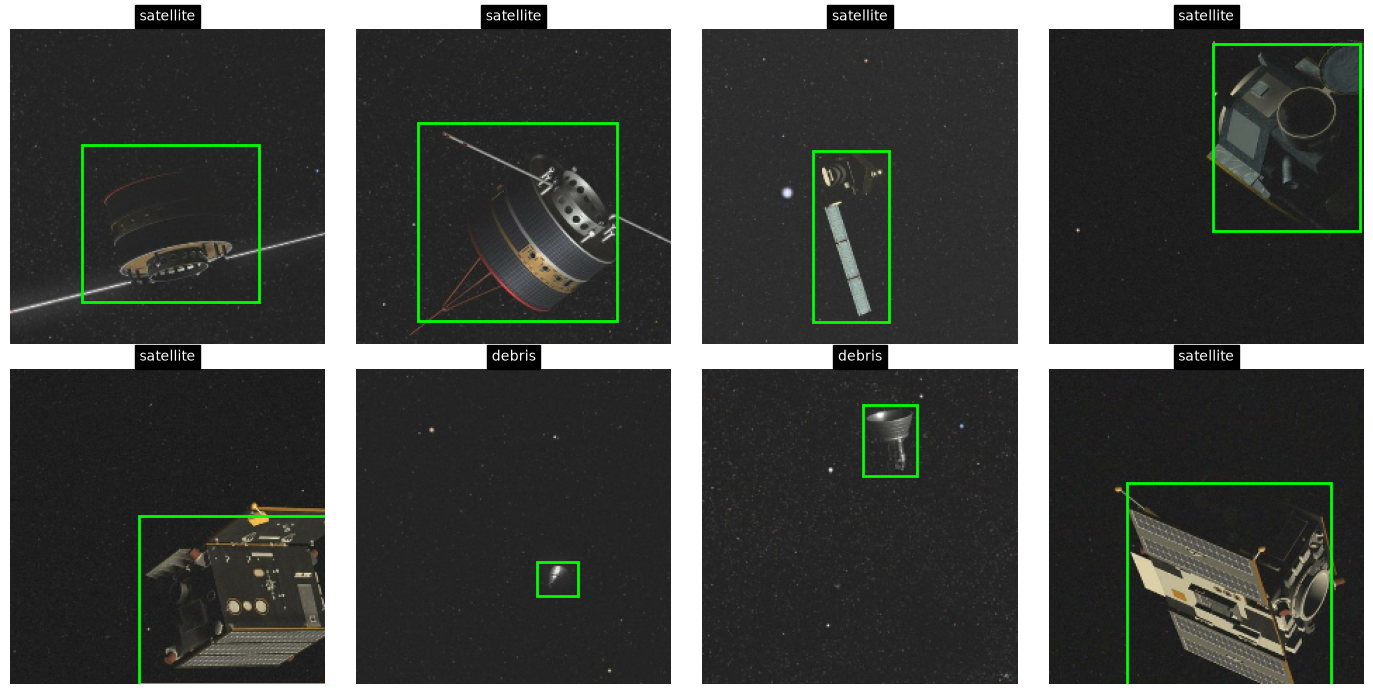

In [20]:
for images, targets in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i in range(min(8, len(images))):
        img = images[i].numpy()
        cls_id = int(targets['class_output'][i].numpy())
        ymin, xmin, ymax, xmax = targets['bbox_output'][i].numpy()

        h, w, _ = img.shape
        box_y = ymin * h
        box_x = xmin * w
        box_h = (ymax - ymin) * h
        box_w = (xmax - xmin) * w

        axes[i].imshow(img)
        rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='lime', facecolor='none')
        axes[i].add_patch(rect)
        axes[i].set_title(f"{CLASS_NAMES[cls_id]}", color='white', backgroundcolor='black', fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
    break


# Conversion des images en HSV 

In [21]:
# from pathlib import Path

# import matplotlib.pyplot as plt
# import numpy as np
# from matplotlib.colors import rgb_to_hsv
# from PIL import Image

# images_dir = Path("data/test/images")
# image_paths = sorted(
#     path for path in images_dir.iterdir()
#     if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
# )[:20]
# #
# # Bornes reglables des trois composantes HSV : H (teinte), S (saturation), V (luminosite).
# # Pour les modifier, conserver des valeurs comprises entre 0.0 et 1.0.
# hue_range = (0.0, 1.0)
# saturation_range = (0.0, 1.0)
# value_range = (0.05, 1.0)

# # Reinitialise les resultats pour ne pas reutiliser ceux d'une execution precedente.
# hsv_images = []

# # Traite chaque image individuellement.
# for image_path in image_paths:
#     # Charge l'image en RGB et normalise ses pixels entre 0 et 1.
#     arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0

#     # Convertit l'image RGB dans l'espace HSV.
#     hsv = rgb_to_hsv(arr)

#     # Construit un masque qui conserve les surfaces sombres du satellite et ses reflets.
#     mask = (
#         (hsv[:, :, 0] >= hue_range[0]) & (hsv[:, :, 0] <= hue_range[1])
#         & (hsv[:, :, 1] >= saturation_range[0]) & (hsv[:, :, 1] <= saturation_range[1])
#         & (hsv[:, :, 2] >= value_range[0]) & (hsv[:, :, 2] <= value_range[1])
#     )

#     # Met a zero les pixels du fond qui ne respectent pas les plages HSV.
#     hsv_filtered = hsv.copy()
#     hsv_filtered[~mask] = 0.0
#     hsv_images.append(hsv_filtered)

# # Affiche les images par pages de 10.
# images_per_page = 10
# for page_start in range(0, len(image_paths), images_per_page):
#     page_paths = image_paths[page_start:page_start + images_per_page]
#     page_hsv = hsv_images[page_start:page_start + images_per_page]
#     figure, axes = plt.subplots(len(page_paths), 2, figsize=(10, 3 * len(page_paths)))
#     axes = np.atleast_2d(axes)

#     # Affiche chaque paire RGB/HSV avec le nom du fichier.
#     for row, (image_path, hsv) in enumerate(zip(page_paths, page_hsv)):
#         arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0
#         axes[row, 0].imshow(arr)
#         axes[row, 0].set_title(f"RGB - {image_path.name}")
#         axes[row, 1].imshow(hsv)
#         axes[row, 1].set_title("HSV filtre HSV")
#         axes[row, 0].axis("off")
#         axes[row, 1].axis("off")

#     # Ajuste la mise en page, affiche la page et libere la figure.
#     figure.tight_layout()
#     plt.show()
#     plt.close(figure)

# print(f"{len(hsv_images)} images filtrees avec le reglage HSV.")

## 5. Construction du modèle multi-tâches

Construction d'un réseau convolutif. Ce modèle possède deux sorties :

- `class_output` prédit la classe de l'objet ;
- `bbox_output` prédit les quatre coordonnées de sa boîte englobante.

In [22]:
from tensorflow import keras
from tensorflow.keras import layers

# Entrée : image RGB redimensionnée 
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")

x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)

# Sortie classification : une probabilité par classe.
class_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_output",
)(x)

# Sortie localisation : quatre coordonnées normalisées entre 0 et 1.
bbox_output = layers.Dense(
    4,
    activation="sigmoid",
    name="bbox_output",
)(x)

model = keras.Model(
    inputs=inputs,
    outputs={
        "class_output": class_output,
        "bbox_output": bbox_output,
    },
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss={
        "class_output": keras.losses.SparseCategoricalCrossentropy(),
        "bbox_output": keras.losses.Huber(),
    },
    metrics={
        "class_output": ["accuracy"],
        "bbox_output": ["mae"],
    },
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 224, 224,  │        896 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 112, 112,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_3[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv2d_5[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │        516 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 2)         │        258 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Aperçu du résultat à chaque epoch

Le callback prend le premier élément du jeu de validation après chaque epoch. Il affiche la classe prédite et la boîte englobante prédite.

In [23]:
class EpochPreviewCallback(keras.callbacks.Callback):
    def __init__(self, dataset, class_names):
        super().__init__()
        self.class_names = class_names
        self.examples_by_class = {class_id: [] for class_id in range(len(class_names))}

        for images, targets in dataset:
            for index in range(images.shape[0]):
                class_id = int(targets["class_output"][index].numpy())
                self.examples_by_class[class_id].append({
                    "image": images[index].numpy(),
                    "bbox": targets["bbox_output"][index].numpy(),
                })

    def _draw_example(self, example, predicted_class_id, predicted_bbox, epoch, class_id):
        image_array = example["image"]
        true_bbox = example["bbox"]
        image_height, image_width, _ = image_array.shape

        predicted_ymin, predicted_xmin, predicted_ymax, predicted_xmax = predicted_bbox
        true_ymin, true_xmin, true_ymax, true_xmax = true_bbox

        figure, axis = plt.subplots(figsize=(6, 6))
        axis.imshow(image_array)

        predicted_rectangle = patches.Rectangle(
            (
                predicted_xmin * image_width,
                predicted_ymin * image_height,
            ),
            (predicted_xmax - predicted_xmin) * image_width,
            (predicted_ymax - predicted_ymin) * image_height,
            linewidth=2,
            edgecolor="red",
            facecolor="none",
            label="Prédiction",
        )
        true_rectangle = patches.Rectangle(
            (
                true_xmin * image_width,
                true_ymin * image_height,
            ),
            (true_xmax - true_xmin) * image_width,
            (true_ymax - true_ymin) * image_height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none",
            linestyle="--",
            label="Vérité terrain",
        )

        axis.add_patch(predicted_rectangle)
        axis.add_patch(true_rectangle)
        axis.set_title(
            f"Epoch {epoch + 1} | Réel : {self.class_names[class_id]} "
            f"| Prévu : {self.class_names[predicted_class_id]}"
        )
        axis.legend()
        axis.axis("off")
        figure.tight_layout()
        plt.show()
        return figure

    def on_epoch_end(self, epoch, logs=None):
        for class_id, class_name in enumerate(self.class_names):
            examples = self.examples_by_class[class_id]
            example = examples[np.random.randint(len(examples))]
            image = example["image"][np.newaxis, ...]
            prediction = self.model.predict(image, verbose=0)
            predicted_class_id = int(np.argmax(prediction["class_output"][0]))
            predicted_bbox = prediction["bbox_output"][0]

            figure = self._draw_example(
                example,
                predicted_class_id,
                predicted_bbox,
                epoch,
                class_id,
            )

            if wandb.run is not None:
                wandb.log({
                    f"epoch_preview_{class_name}": wandb.Image(
                        figure,
                        caption=(
                            f"Epoch {epoch + 1} - exemple {class_name} - "
                            f"prévu: {self.class_names[predicted_class_id]}"
                        ),
                    )
                })

            plt.close(figure)

## 6. Suivi de l'expérience avec Weights & Biases

`wandb` enregistre les paramètres, les pertes et les métriques de chaque entraînement. Il permet de comparer plusieurs expériences dans un tableau de bord.

In [24]:
import wandb
from wandb.integration.keras import WandbMetricsLogger

## 7. Entraînement du modèle

À chaque epoch, TensorFlow lit les images, calcule les deux prédictions, mesure les deux erreurs puis met à jour les poids du réseau. W&B reçoit les métriques grâce au callback `WandbMetricsLogger`.

Epoch 1/25


/home/parriaultlyse/Documents/5A/projet_deep_learning/ia_deep_learning_projet/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - bbox_output_loss: 0.0180 - bbox_output_mae: 0.1556 - class_output_accuracy: 0.9116 - class_output_loss: 0.2904 - loss: 0.3081

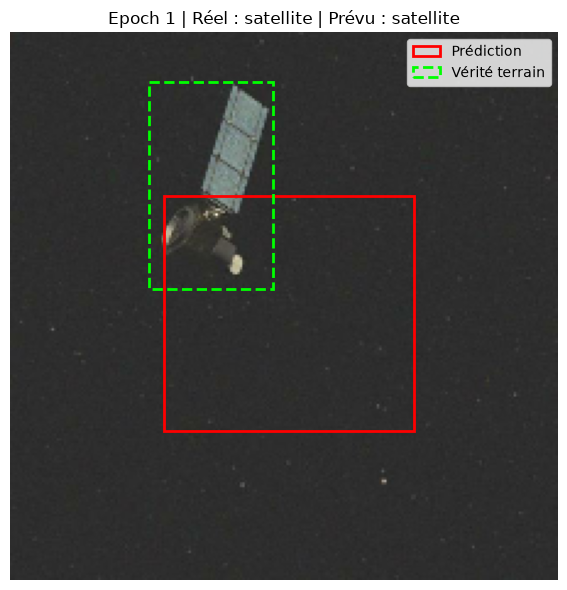

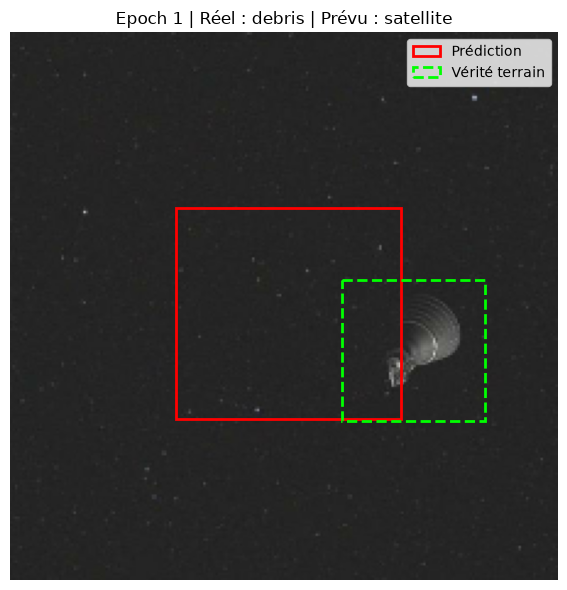

132/132 ━━━━━━━━━━━━━━━━━━━━ 46s 338ms/step - bbox_output_loss: 0.0180 - bbox_output_mae: 0.1556 - class_output_accuracy: 0.9116 - class_output_loss: 0.2904 - loss: 0.3081 - val_bbox_output_loss: 0.0163 - val_bbox_output_mae: 0.1476 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.3084 - val_loss: 0.3258
Epoch 2/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - bbox_output_loss: 0.0164 - bbox_output_mae: 0.1481 - class_output_accuracy: 0.9116 - class_output_loss: 0.2775 - loss: 0.2947

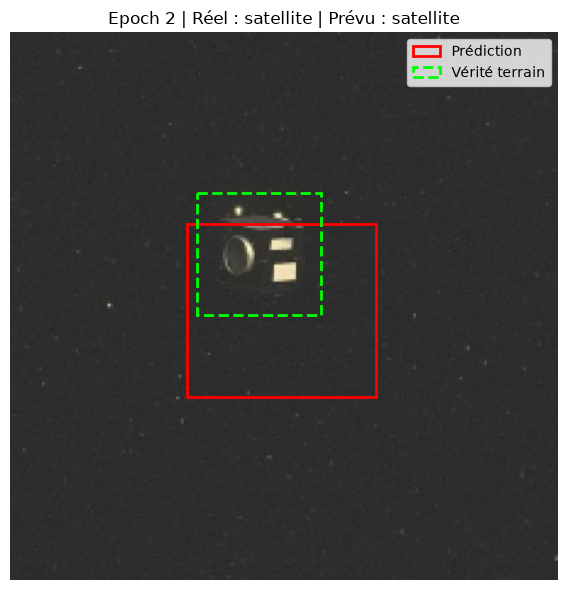

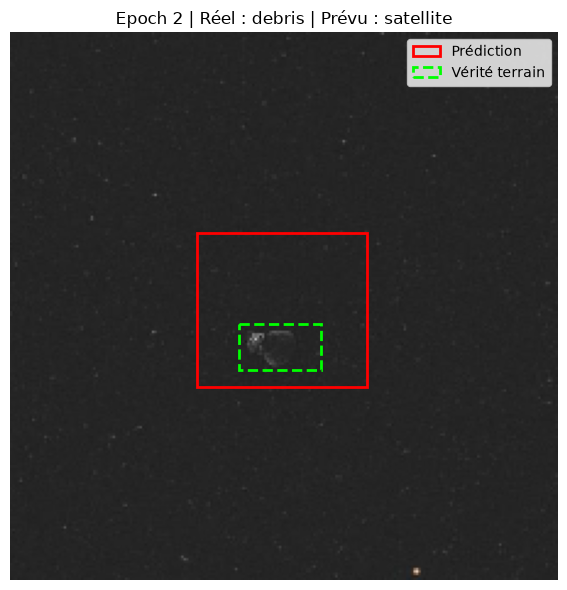

132/132 ━━━━━━━━━━━━━━━━━━━━ 44s 335ms/step - bbox_output_loss: 0.0164 - bbox_output_mae: 0.1481 - class_output_accuracy: 0.9116 - class_output_loss: 0.2775 - loss: 0.2947 - val_bbox_output_loss: 0.0158 - val_bbox_output_mae: 0.1458 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2704 - val_loss: 0.2870
Epoch 3/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - bbox_output_loss: 0.0158 - bbox_output_mae: 0.1442 - class_output_accuracy: 0.9116 - class_output_loss: 0.2581 - loss: 0.2737

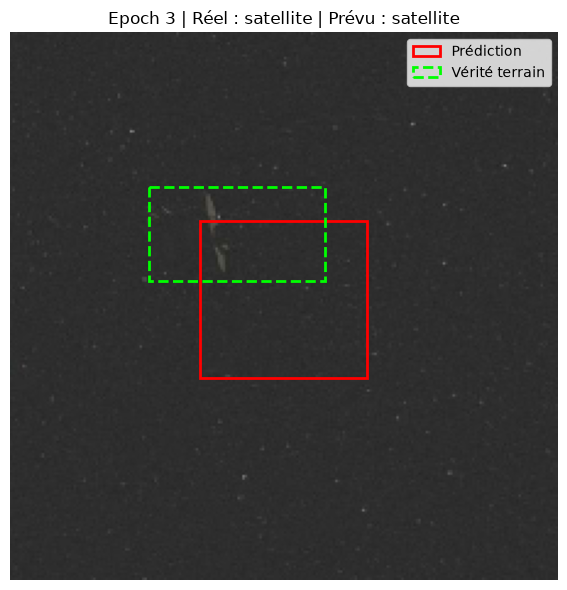

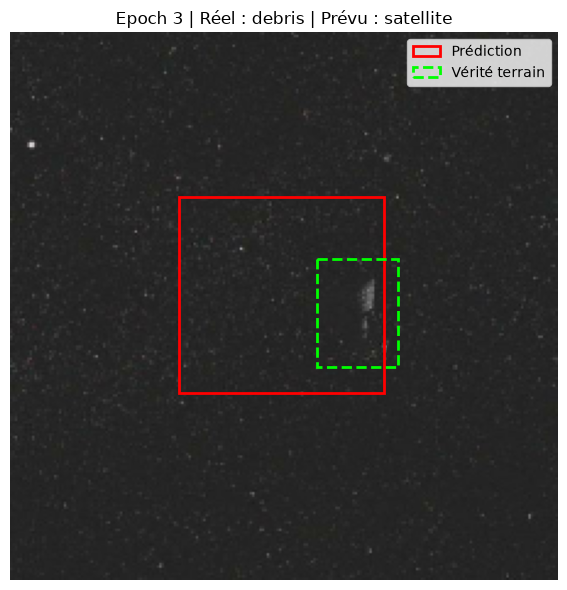

132/132 ━━━━━━━━━━━━━━━━━━━━ 47s 355ms/step - bbox_output_loss: 0.0158 - bbox_output_mae: 0.1442 - class_output_accuracy: 0.9116 - class_output_loss: 0.2581 - loss: 0.2737 - val_bbox_output_loss: 0.0161 - val_bbox_output_mae: 0.1449 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2552 - val_loss: 0.2720
Epoch 4/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - bbox_output_loss: 0.0161 - bbox_output_mae: 0.1456 - class_output_accuracy: 0.9116 - class_output_loss: 0.2276 - loss: 0.2443

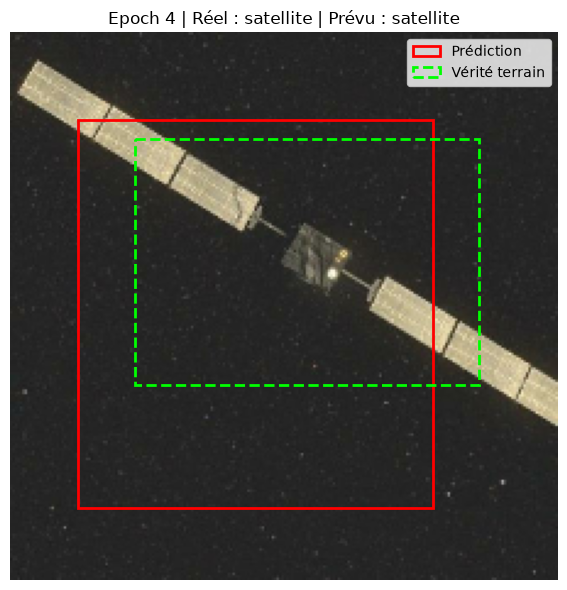

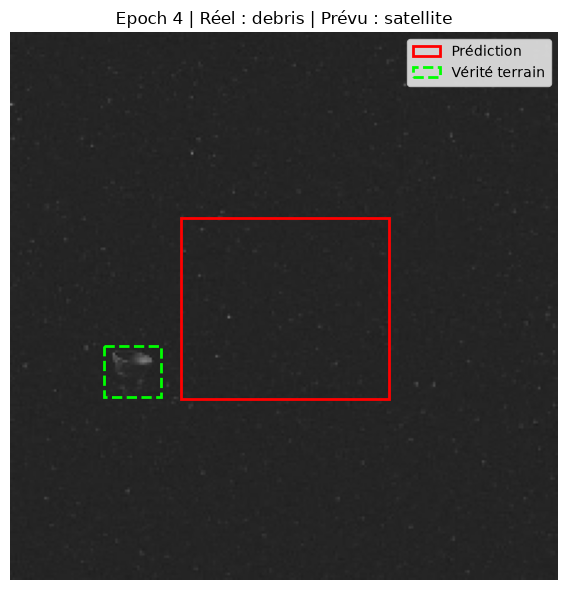

132/132 ━━━━━━━━━━━━━━━━━━━━ 48s 362ms/step - bbox_output_loss: 0.0161 - bbox_output_mae: 0.1456 - class_output_accuracy: 0.9116 - class_output_loss: 0.2276 - loss: 0.2443 - val_bbox_output_loss: 0.0168 - val_bbox_output_mae: 0.1470 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2549 - val_loss: 0.2725
Epoch 5/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1439 - class_output_accuracy: 0.9116 - class_output_loss: 0.2165 - loss: 0.2326

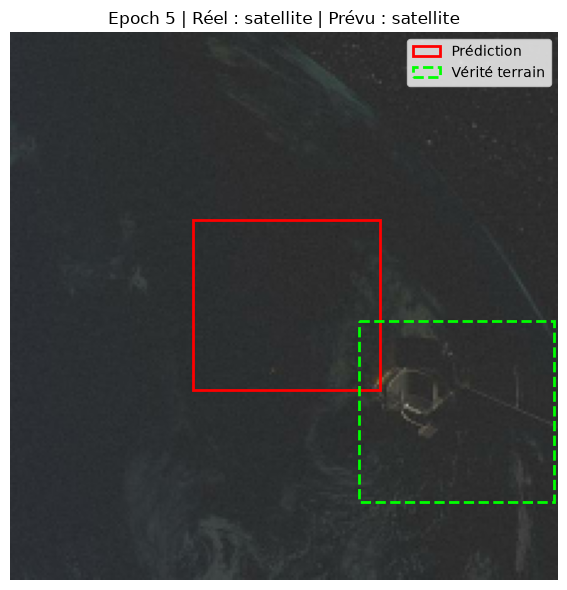

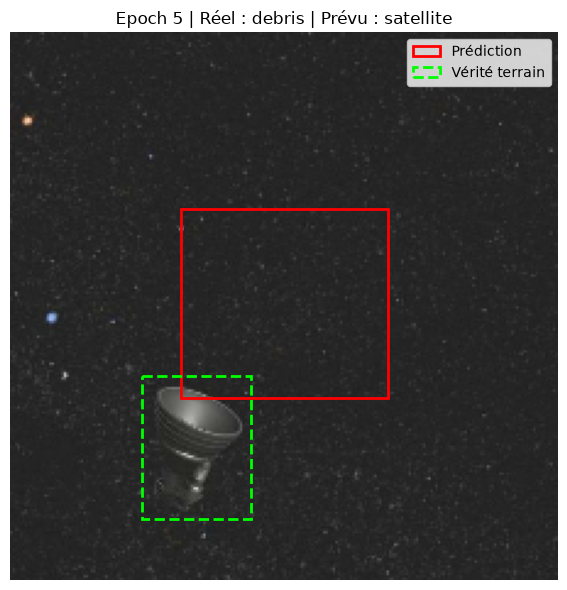

132/132 ━━━━━━━━━━━━━━━━━━━━ 49s 373ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1439 - class_output_accuracy: 0.9116 - class_output_loss: 0.2165 - loss: 0.2326 - val_bbox_output_loss: 0.0160 - val_bbox_output_mae: 0.1455 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2141 - val_loss: 0.2301
Epoch 6/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - bbox_output_loss: 0.0156 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9116 - class_output_loss: 0.2112 - loss: 0.2267

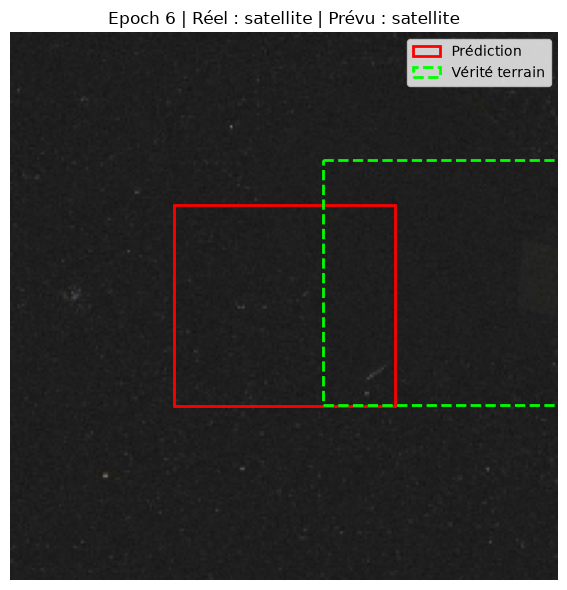

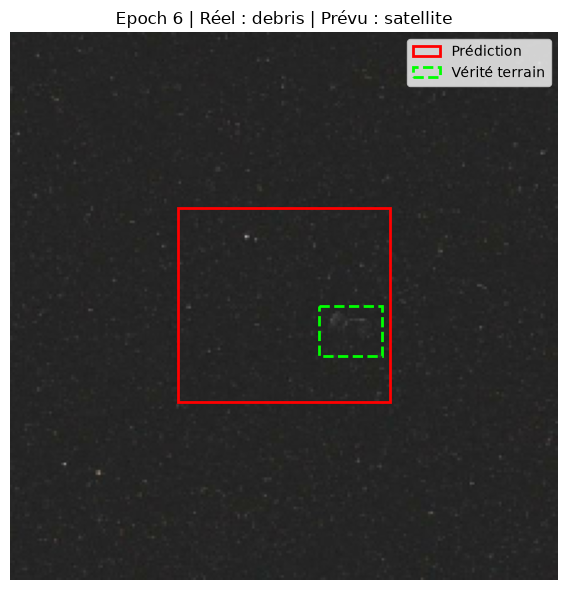

132/132 ━━━━━━━━━━━━━━━━━━━━ 51s 387ms/step - bbox_output_loss: 0.0156 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9116 - class_output_loss: 0.2112 - loss: 0.2267 - val_bbox_output_loss: 0.0165 - val_bbox_output_mae: 0.1470 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2250 - val_loss: 0.2421
Epoch 7/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1437 - class_output_accuracy: 0.9116 - class_output_loss: 0.2098 - loss: 0.2251

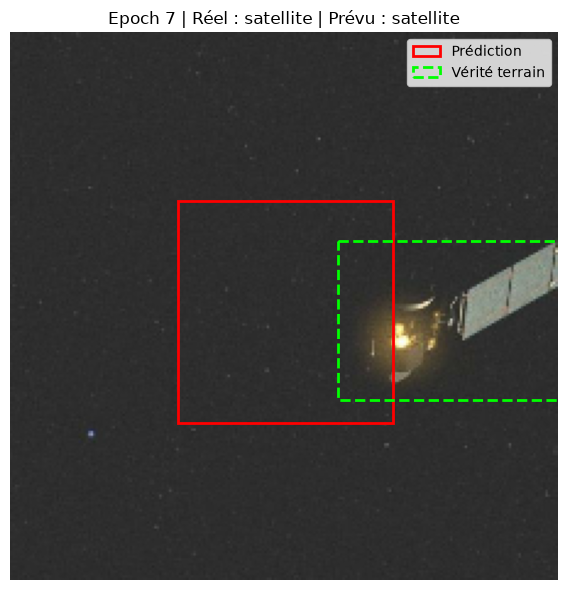

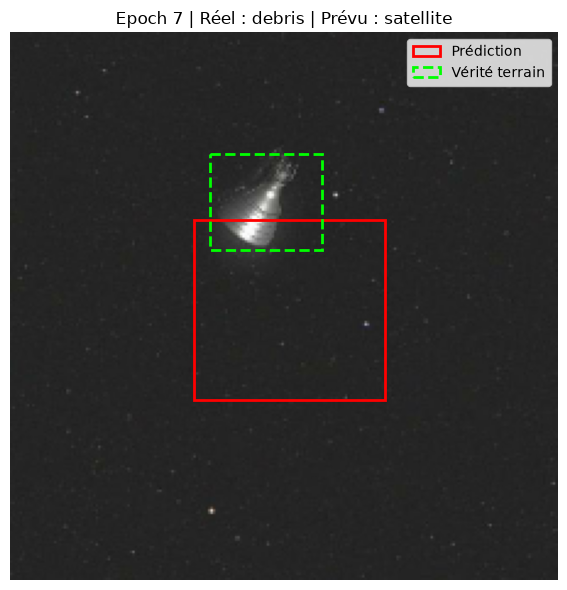

132/132 ━━━━━━━━━━━━━━━━━━━━ 50s 383ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1437 - class_output_accuracy: 0.9116 - class_output_loss: 0.2098 - loss: 0.2251 - val_bbox_output_loss: 0.0163 - val_bbox_output_mae: 0.1478 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2686 - val_loss: 0.2846
Epoch 8/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - bbox_output_loss: 0.0152 - bbox_output_mae: 0.1427 - class_output_accuracy: 0.9116 - class_output_loss: 0.2052 - loss: 0.2211

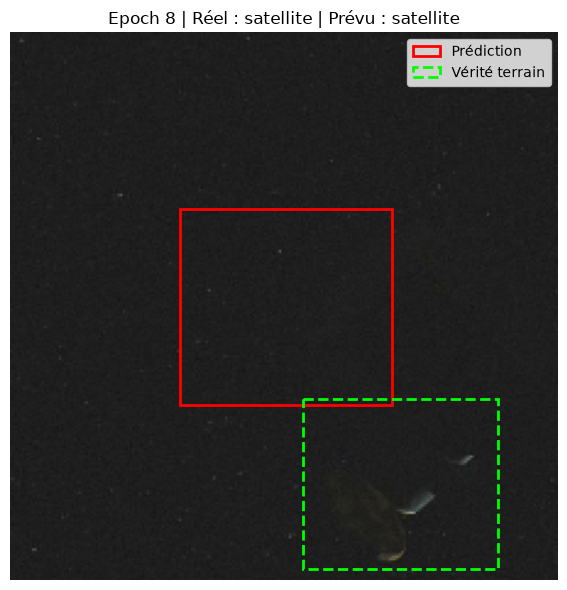

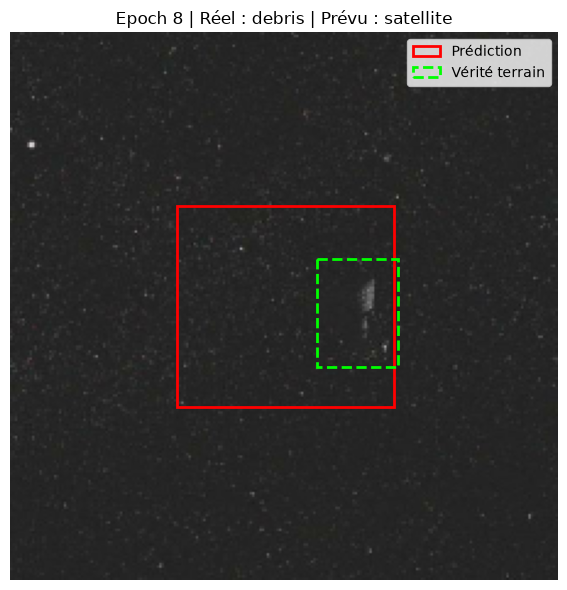

132/132 ━━━━━━━━━━━━━━━━━━━━ 51s 390ms/step - bbox_output_loss: 0.0152 - bbox_output_mae: 0.1427 - class_output_accuracy: 0.9116 - class_output_loss: 0.2052 - loss: 0.2211 - val_bbox_output_loss: 0.0160 - val_bbox_output_mae: 0.1459 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2053 - val_loss: 0.2216
Epoch 9/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - bbox_output_loss: 0.0153 - bbox_output_mae: 0.1425 - class_output_accuracy: 0.9116 - class_output_loss: 0.1970 - loss: 0.2129

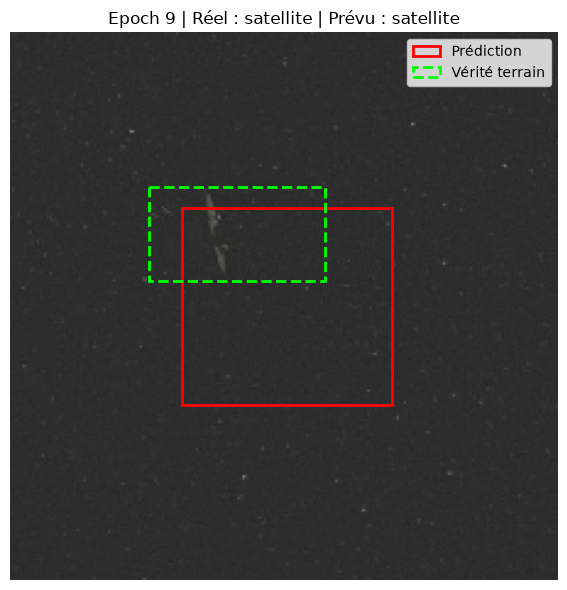

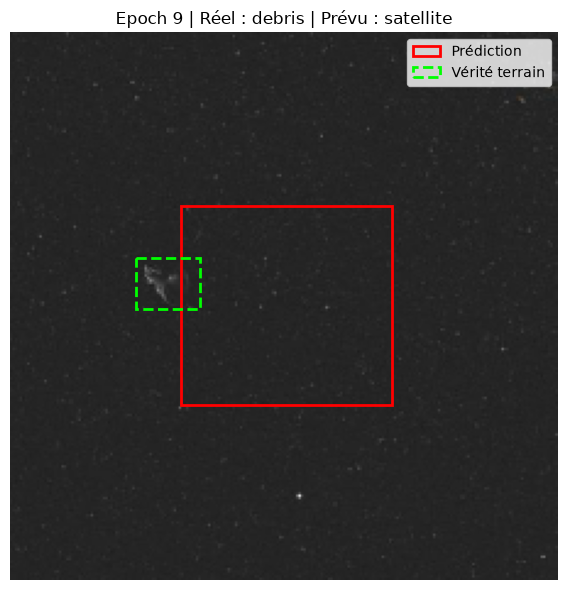

132/132 ━━━━━━━━━━━━━━━━━━━━ 53s 399ms/step - bbox_output_loss: 0.0153 - bbox_output_mae: 0.1425 - class_output_accuracy: 0.9116 - class_output_loss: 0.1970 - loss: 0.2129 - val_bbox_output_loss: 0.0165 - val_bbox_output_mae: 0.1472 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2421 - val_loss: 0.2593
Epoch 10/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - bbox_output_loss: 0.0155 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9116 - class_output_loss: 0.1956 - loss: 0.2115

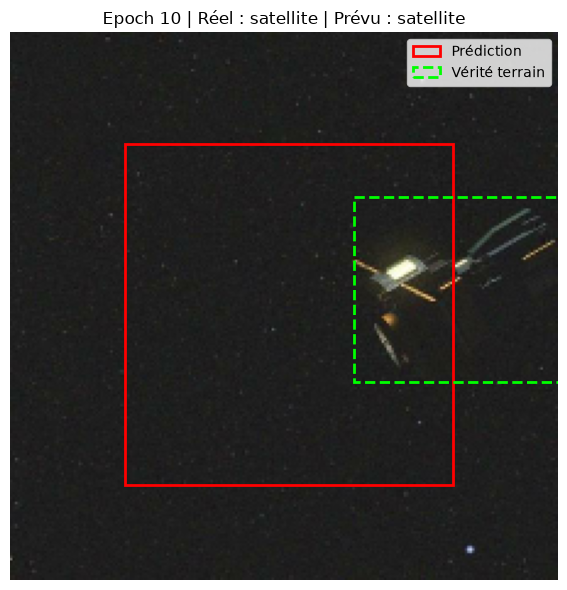

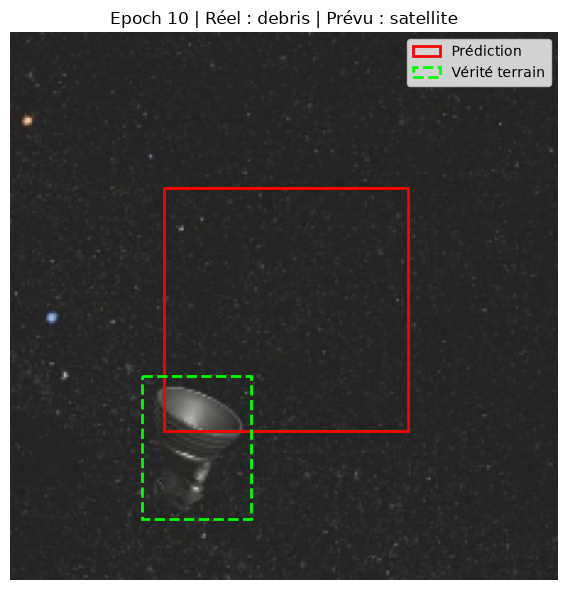

132/132 ━━━━━━━━━━━━━━━━━━━━ 54s 407ms/step - bbox_output_loss: 0.0155 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9116 - class_output_loss: 0.1956 - loss: 0.2115 - val_bbox_output_loss: 0.0188 - val_bbox_output_mae: 0.1542 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.1956 - val_loss: 0.2149
Epoch 11/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1439 - class_output_accuracy: 0.9116 - class_output_loss: 0.1836 - loss: 0.1996

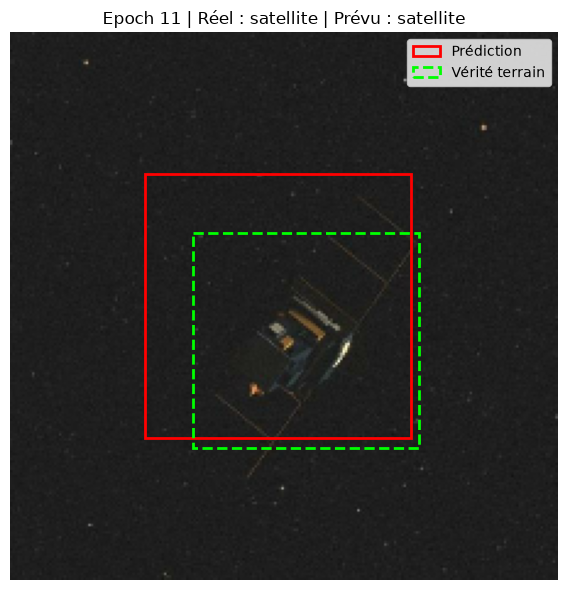

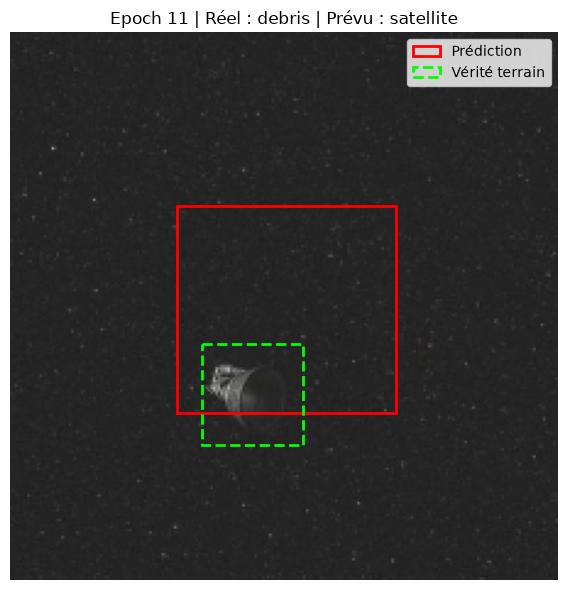

132/132 ━━━━━━━━━━━━━━━━━━━━ 51s 386ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1439 - class_output_accuracy: 0.9116 - class_output_loss: 0.1836 - loss: 0.1996 - val_bbox_output_loss: 0.0182 - val_bbox_output_mae: 0.1512 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.1945 - val_loss: 0.2127
Epoch 12/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1442 - class_output_accuracy: 0.9116 - class_output_loss: 0.1787 - loss: 0.1950

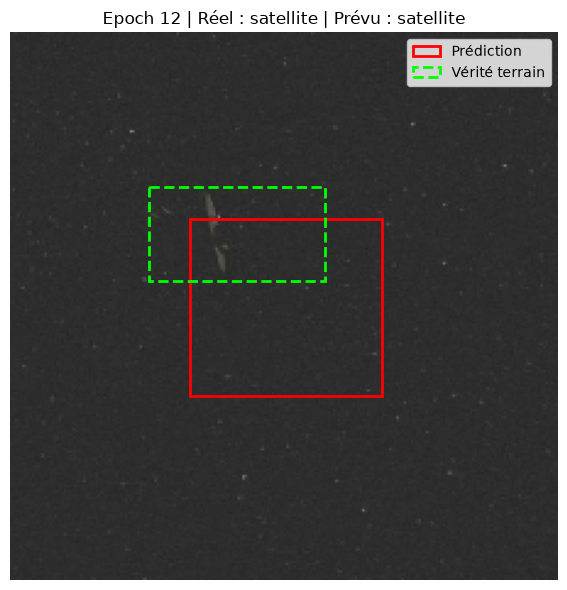

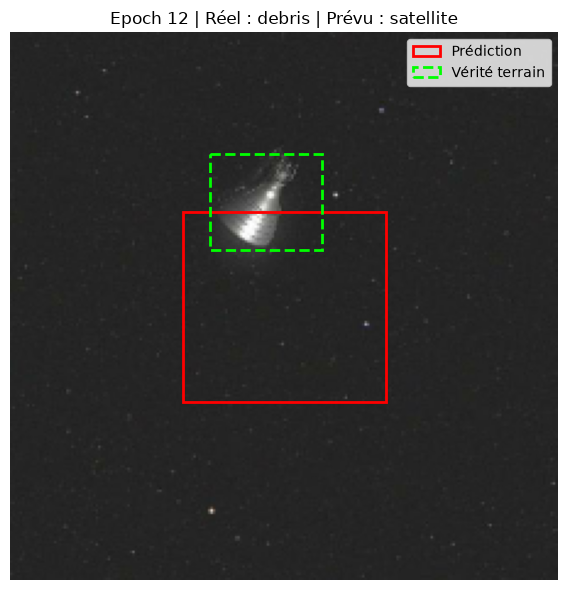

132/132 ━━━━━━━━━━━━━━━━━━━━ 52s 394ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1442 - class_output_accuracy: 0.9116 - class_output_loss: 0.1787 - loss: 0.1950 - val_bbox_output_loss: 0.0175 - val_bbox_output_mae: 0.1497 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.1766 - val_loss: 0.1945
Epoch 13/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - bbox_output_loss: 0.0158 - bbox_output_mae: 0.1438 - class_output_accuracy: 0.9116 - class_output_loss: 0.1719 - loss: 0.1877

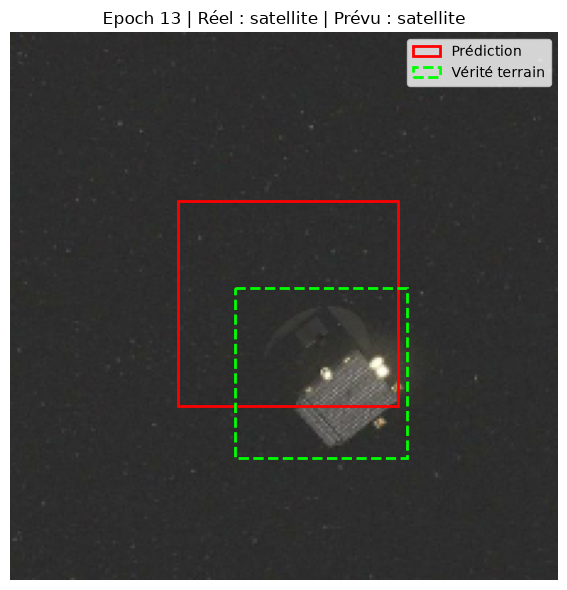

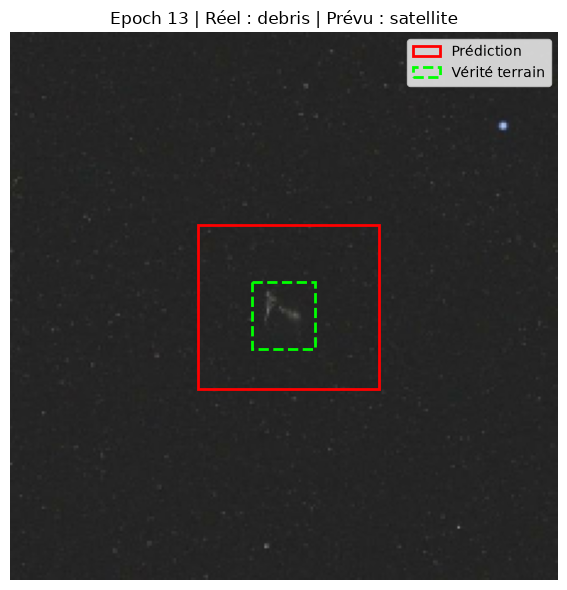

132/132 ━━━━━━━━━━━━━━━━━━━━ 52s 395ms/step - bbox_output_loss: 0.0158 - bbox_output_mae: 0.1438 - class_output_accuracy: 0.9116 - class_output_loss: 0.1719 - loss: 0.1877 - val_bbox_output_loss: 0.0190 - val_bbox_output_mae: 0.1530 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.1745 - val_loss: 0.1934
Epoch 14/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - bbox_output_loss: 0.0164 - bbox_output_mae: 0.1456 - class_output_accuracy: 0.9116 - class_output_loss: 0.1659 - loss: 0.1823

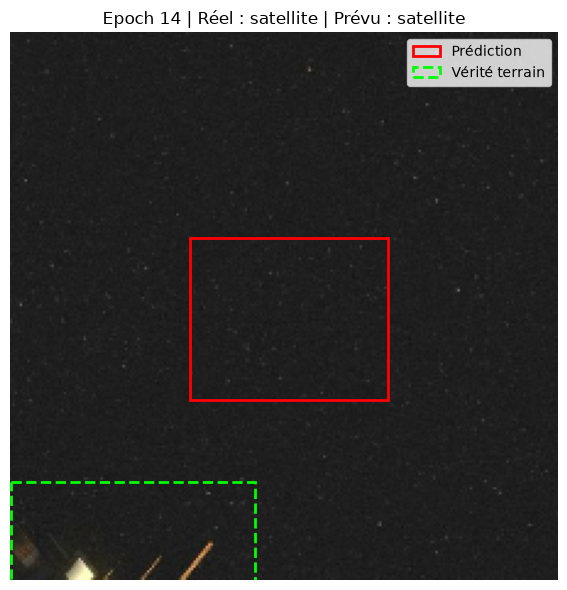

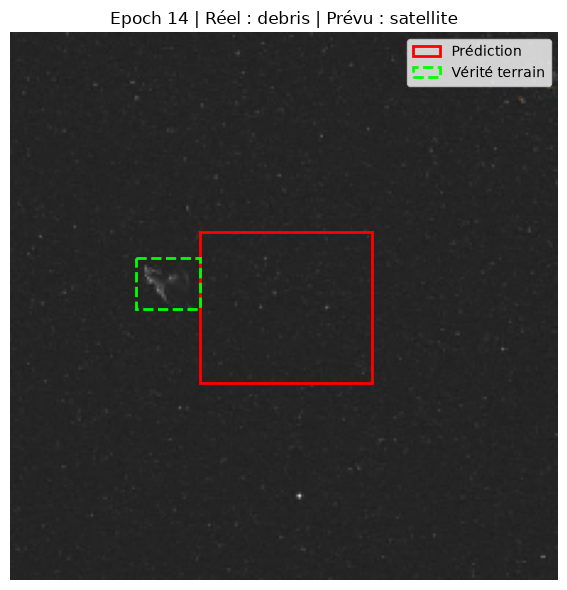

132/132 ━━━━━━━━━━━━━━━━━━━━ 54s 409ms/step - bbox_output_loss: 0.0164 - bbox_output_mae: 0.1456 - class_output_accuracy: 0.9116 - class_output_loss: 0.1659 - loss: 0.1823 - val_bbox_output_loss: 0.0187 - val_bbox_output_mae: 0.1539 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.1551 - val_loss: 0.1741
Epoch 15/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - bbox_output_loss: 0.0161 - bbox_output_mae: 0.1453 - class_output_accuracy: 0.9036 - class_output_loss: 0.1889 - loss: 0.2046

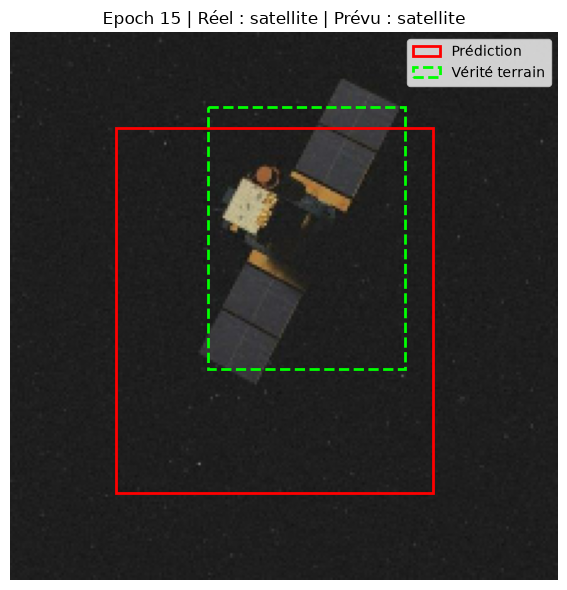

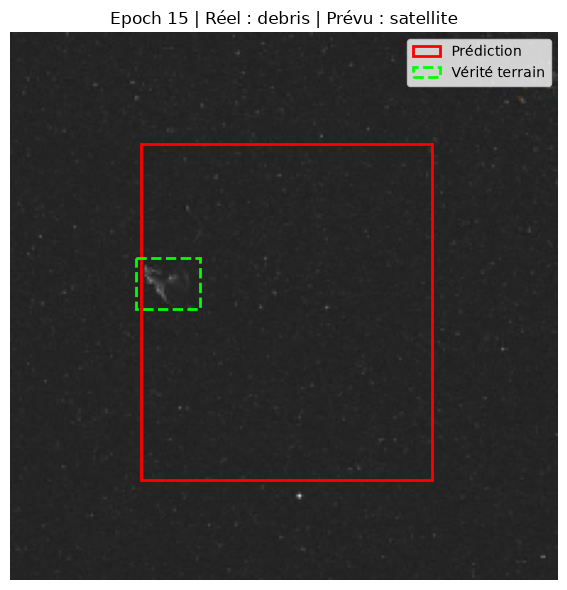

132/132 ━━━━━━━━━━━━━━━━━━━━ 53s 403ms/step - bbox_output_loss: 0.0161 - bbox_output_mae: 0.1453 - class_output_accuracy: 0.9036 - class_output_loss: 0.1889 - loss: 0.2046 - val_bbox_output_loss: 0.0222 - val_bbox_output_mae: 0.1693 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2794 - val_loss: 0.3024
Epoch 16/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - bbox_output_loss: 0.0166 - bbox_output_mae: 0.1491 - class_output_accuracy: 0.9116 - class_output_loss: 0.3379 - loss: 0.3554

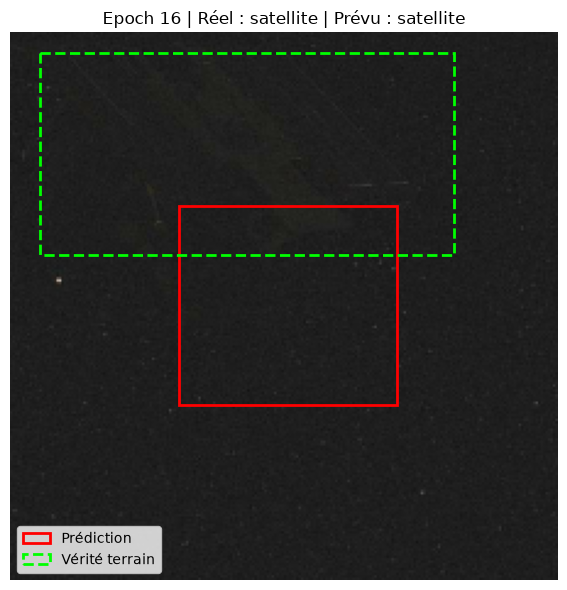

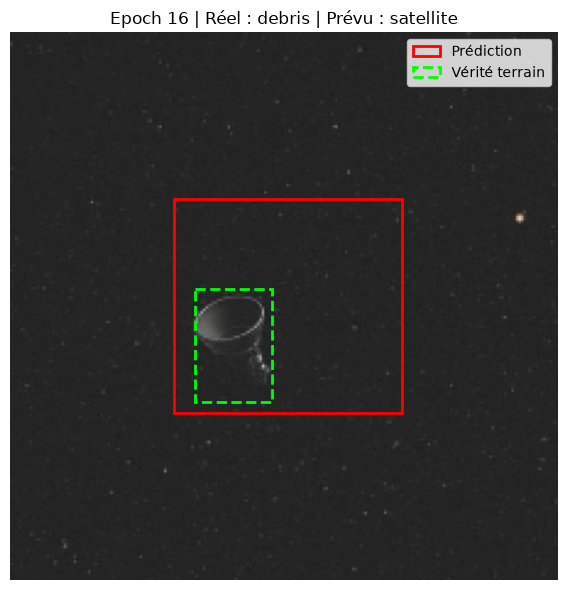

132/132 ━━━━━━━━━━━━━━━━━━━━ 53s 399ms/step - bbox_output_loss: 0.0166 - bbox_output_mae: 0.1491 - class_output_accuracy: 0.9116 - class_output_loss: 0.3379 - loss: 0.3554 - val_bbox_output_loss: 0.0166 - val_bbox_output_mae: 0.1494 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2965 - val_loss: 0.3139
Epoch 17/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1457 - class_output_accuracy: 0.9116 - class_output_loss: 0.2813 - loss: 0.2973

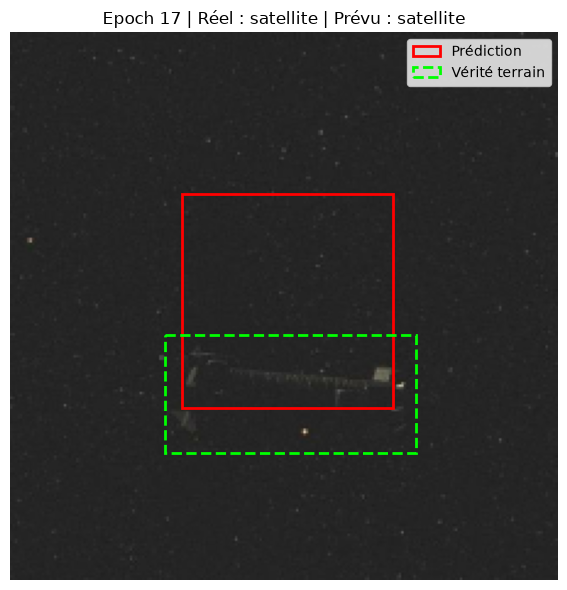

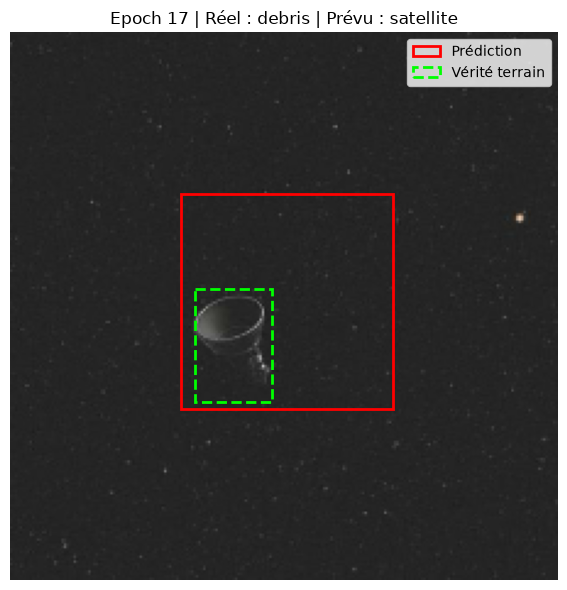

132/132 ━━━━━━━━━━━━━━━━━━━━ 54s 406ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1457 - class_output_accuracy: 0.9116 - class_output_loss: 0.2813 - loss: 0.2973 - val_bbox_output_loss: 0.0165 - val_bbox_output_mae: 0.1485 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2808 - val_loss: 0.2978
Epoch 18/25
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1458 - class_output_accuracy: 0.9116 - class_output_loss: 0.2734 - loss: 0.2898

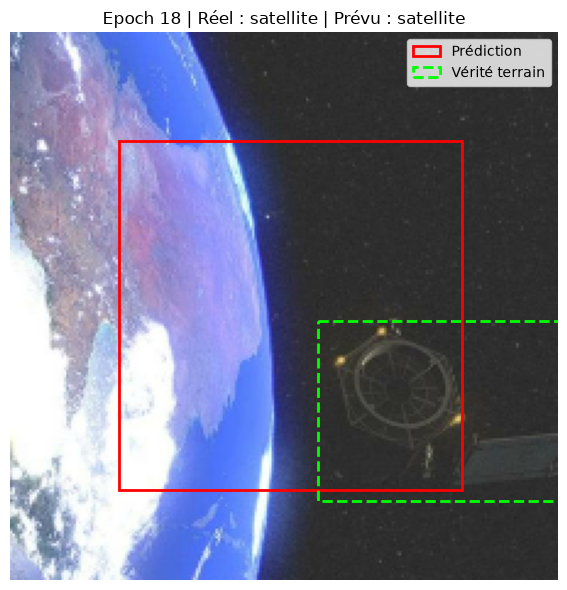

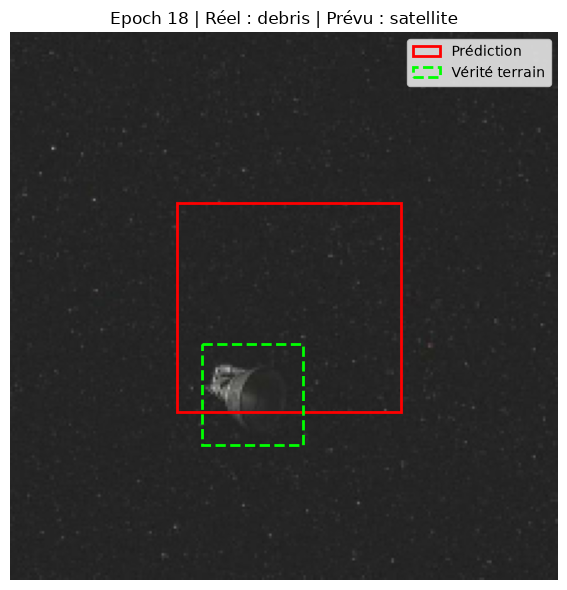

132/132 ━━━━━━━━━━━━━━━━━━━━ 52s 391ms/step - bbox_output_loss: 0.0157 - bbox_output_mae: 0.1458 - class_output_accuracy: 0.9116 - class_output_loss: 0.2734 - loss: 0.2898 - val_bbox_output_loss: 0.0163 - val_bbox_output_mae: 0.1475 - val_class_output_accuracy: 0.9121 - val_class_output_loss: 0.2448 - val_loss: 0.2616


In [25]:
import wandb
from wandb.integration.keras import WandbMetricsLogger

EPOCHS = 25

wandb.login()

if wandb.run is not None:
    wandb.finish()

wandb.init(
    project="detecteur-objets-spatiaux",
    name="cnn-binaire-classification-localisation",
    config={
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "num_classes": NUM_CLASSES,
        "class_names": CLASS_NAMES,
        "learning_rate": 0.001,
        "epochs": EPOCHS,
    },
)

wandb_metrics = WandbMetricsLogger(log_freq="epoch")
epoch_preview = EpochPreviewCallback(val_ds, CLASS_NAMES)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        wandb_metrics,
        epoch_preview,
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        ),
    ],
)

## 8. Visualisation des courbes d'apprentissage

Les courbes permettent de comparer les performances sur les données d'entraînement et de validation.

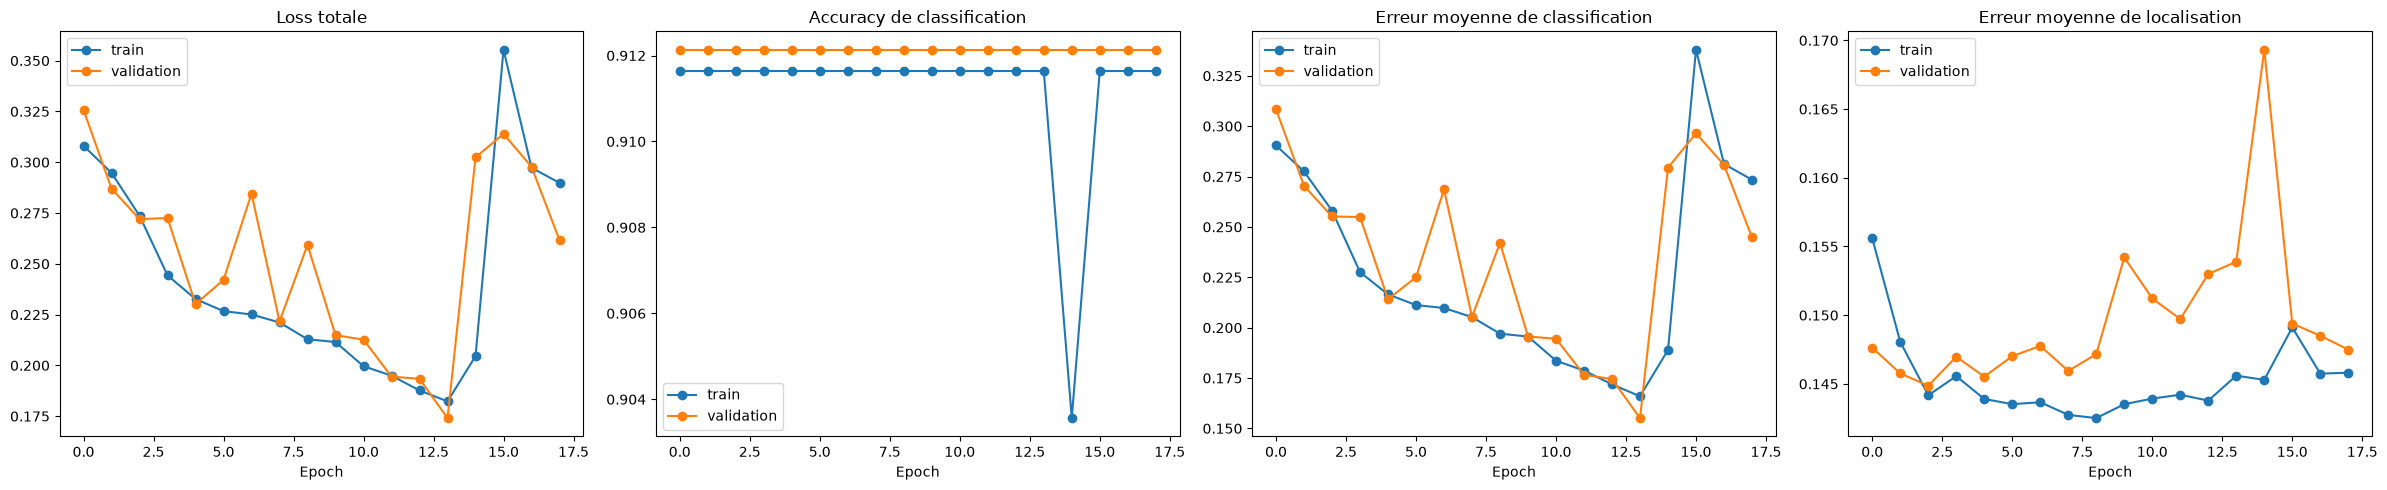

In [26]:
metrics = history.history

figure, axes = plt.subplots(1, 4, figsize=(24, 5))

axes[0].plot(history.epoch, metrics["loss"], "o-", label="train")
axes[0].plot(history.epoch, metrics["val_loss"], "o-", label="validation")
axes[0].set_title("Loss totale")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.epoch, metrics["class_output_accuracy"], "o-", label="train")
axes[1].plot(history.epoch, metrics["val_class_output_accuracy"], "o-", label="validation")
axes[1].set_title("Accuracy de classification")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(history.epoch, metrics["class_output_loss"], "o-", label="train")
axes[2].plot(history.epoch, metrics["val_class_output_loss"], "o-", label="validation")
axes[2].set_title("Erreur moyenne de classification")
axes[2].set_xlabel("Epoch")
axes[2].legend()

axes[3].plot(history.epoch, metrics["bbox_output_mae"], "o-", label="train")
axes[3].plot(history.epoch, metrics["val_bbox_output_mae"], "o-", label="validation")
axes[3].set_title("Erreur moyenne de localisation")
axes[3].set_xlabel("Epoch")
axes[3].legend()



plt.tight_layout()
plt.show()

## 9. Évaluation finale sur le jeu de test

Le jeu de test n'est pas utilisé pour modifier le modèle. Il sert uniquement à mesurer ses performances sur des images qu'il n'a pas vues pendant l'entraînement.

In [27]:
test_results = model.evaluate(test_ds, return_dict=True)

print("Résultats sur le jeu de test :")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

if wandb.run is not None:
    wandb.log({f"test/{name}": value for name, value in test_results.items()})
    wandb.finish()

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - bbox_output_loss: 0.0166 - bbox_output_mae: 0.1451 - class_output_accuracy: 0.9106 - class_output_loss: 0.1272 - loss: 0.1462


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Résultats sur le jeu de test :
bbox_output_loss: 0.0166
bbox_output_mae: 0.1451
class_output_accuracy: 0.9106
class_output_loss: 0.1272
loss: 0.1462


epoch/bbox_output_loss,█▄▂▃▂▂▂▁▁▂▂▂▂▄▃▄▂▂
epoch/bbox_output_mae,█▄▂▃▂▂▂▁▁▂▂▂▂▃▂▅▃▃
epoch/class_output_accuracy,██████████████▁███
epoch/class_output_loss,▆▆▅▄▃▃▃▃▂▂▂▂▁▁▂█▆▅
epoch/epoch,▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,▆▆▅▄▃▃▃▃▂▂▂▂▁▁▂█▆▅
epoch/val_bbox_output_loss,▂▁▁▂▁▂▁▁▂▄▄▃▅▄█▂▂▂
epoch/val_bbox_output_mae,▂▁▁▂▁▂▂▁▂▄▃▂▃▄█▂▂▂
epoch/val_class_output_accuracy,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...
